In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [22]:
df = pd.read_csv("email_spam.csv")
df

,Message_ID,Email_Length,Word_Count,Link_Count,Has_Attachment,Spam
0,1,55,8,1,1,1
1,2,42,6,0,0,0
2,3,71,10,3,0,1
3,4,56,8,0,0,0
4,5,87,12,2,1,1
...,...,...,...,...,...,...
95,96,70,8,0,1,0
96,97,55,9,1,1,1
97,98,42,6,0,0,0
98,99,71,11,3,0,1


In [23]:
df.columns

Index(['Message_ID', 'Email_Length', 'Word_Count', 'Link_Count',
       'Has_Attachment', 'Spam'],
      dtype='str')

In [24]:
df.shape


(100, 6)

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Message_ID      100 non-null    int64
 1   Email_Length    100 non-null    int64
 2   Word_Count      100 non-null    int64
 3   Link_Count      100 non-null    int64
 4   Has_Attachment  100 non-null    int64
 5   Spam            100 non-null    int64
dtypes: int64(6)
memory usage: 4.8 KB


In [26]:
df.isnull().sum()

Message_ID        0
Email_Length      0
Word_Count        0
Link_Count        0
Has_Attachment    0
Spam              0
dtype: int64

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df = df.drop_duplicates()
df.shape

(100, 6)

In [29]:
X = df[['Email_Length', 'Word_Count', 'Link_Count', 'Has_Attachment']]
y = df['Spam']

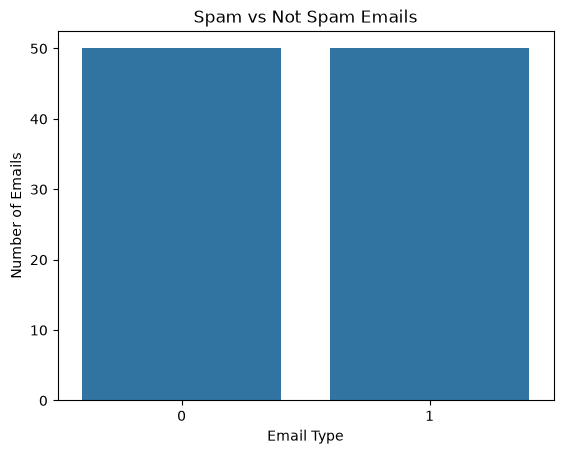

In [30]:
sns.countplot(x="Spam", data=df)
plt.xlabel("Email Type")
plt.ylabel("Number of Emails")
plt.title("Spam vs Not Spam Emails")
plt.show()

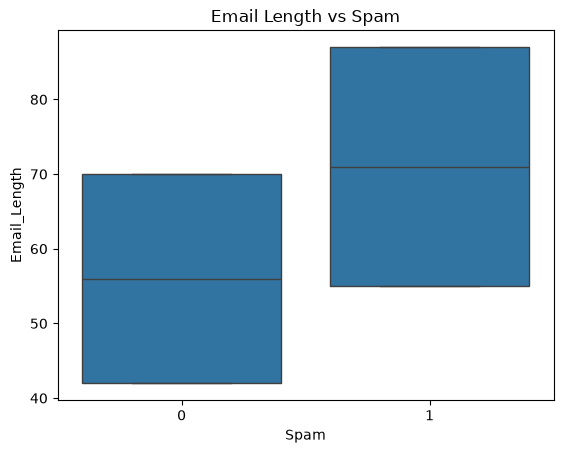

In [31]:
sns.boxplot(data=df, x='Spam', y='Email_Length')
plt.title('Email Length vs Spam')
plt.show()

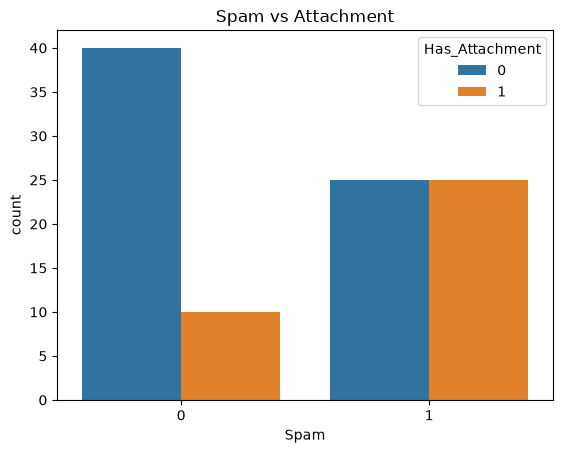

In [32]:
sns.countplot(data=df, x='Spam', hue='Has_Attachment')
plt.title('Spam vs Attachment')
plt.show()

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=24, stratify=y
)

In [34]:
categorical_columns = [
    'Has_Attachment'
]

numerical_columns = [
    'Email_Length',
    'Word_Count',
    'Link_Count'
]

In [35]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns
        ),
        (
            'num',
            'passthrough',
            numerical_columns
        )
    ]
)

In [36]:
dt = LogisticRegression(
    random_state=42,
    class_weight='balanced'
)

In [37]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        random_state=42,
        class_weight='balanced'
    ))
])

In [39]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Email_Length','Word_Count','Link_Count','Has_Attachment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining colu

In [41]:
y_pred = pipeline.predict(X_test)

In [43]:
accuracy = accuracy_score(y_test, y_pred)

In [44]:
print("Accuracy score:", accuracy)

Accuracy score: 1.0


In [45]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [46]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[10,  0],
       [ 0, 10]])

In [47]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



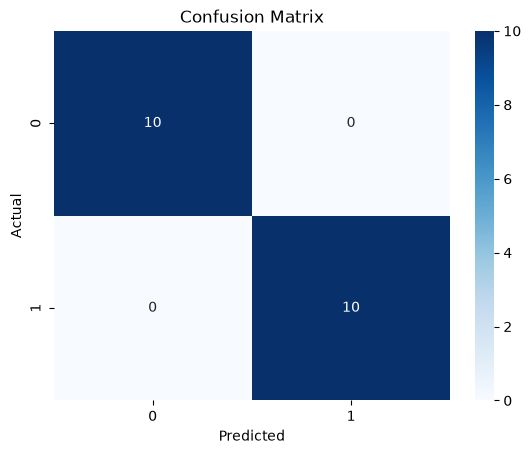

In [ ]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [48]:

import pickle

In [49]:
with open('model.pkl', 'wb') as file:
    pickle.dump(pipeline, file)